In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.cluster import DBSCAN

import warnings
warnings.filterwarnings("ignore")

plt.style.use("ggplot")

In [2]:
df = pd.read_csv("../data/processed_customers.csv")

df.head()

,Gender,Age,Income,Score
0,1.141195,-1.425414,-1.779171,-0.435989
1,1.141195,-1.282367,-1.779171,1.199413
2,-0.876275,-1.353890,-1.739447,-1.720949
3,-0.876275,-1.139319,-1.739447,1.043661
4,-0.876275,-0.567131,-1.699723,-0.397051


In [3]:
print(df.shape)

df.info()

(198, 4)
<class 'pandas.DataFrame'>
RangeIndex: 198 entries, 0 to 197
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Gender  198 non-null    float64
 1   Age     198 non-null    float64
 2   Income  198 non-null    float64
 3   Score   198 non-null    float64
dtypes: float64(4)
memory usage: 6.3 KB


In [4]:
pca = PCA(n_components=2)

pca_data = pca.fit_transform(df)

pca_data[:5]

array([[-0.40967734, -0.8547251 ],
       [-1.42919441, -0.66597411],
       [ 0.01900298, -2.03113691],
       [-1.72317904, -1.71005885],
       [-0.34527602, -1.89409436]])

In [5]:
pca_df = pd.DataFrame(
    pca_data,
    columns=["PC1", "PC2"]
)

pca_df.head()

,PC1,PC2
0,-0.409677,-0.854725
1,-1.429194,-0.665974
2,0.019003,-2.031137
3,-1.723179,-1.710059
4,-0.345276,-1.894094


In [6]:
print("Explained Variance Ratio:")

print(pca.explained_variance_ratio_)

Explained Variance Ratio:
[0.33807564 0.25402715]


In [7]:
print(
    "Total Variance Explained:",
    pca.explained_variance_ratio_.sum()
)

Total Variance Explained: 0.5921027882445435


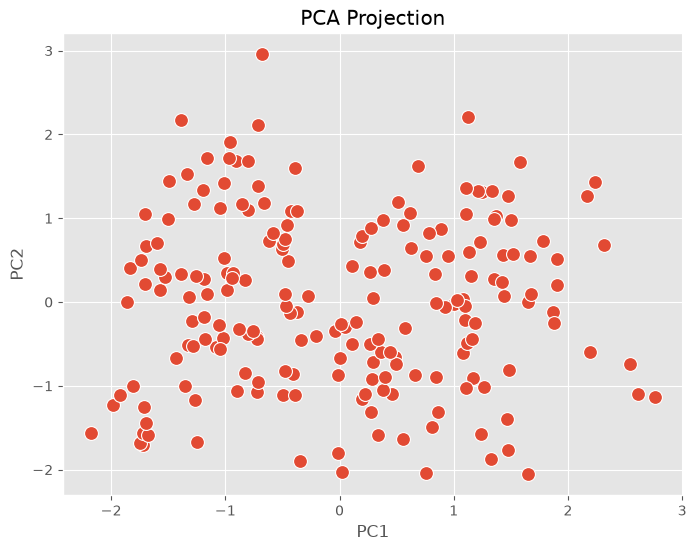

In [8]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    s=100
)

plt.title("PCA Projection")

plt.show()

**Apply K-Means on PCA Data**

In [9]:
kmeans = KMeans(
    n_clusters=5,
    random_state=42
)

kmeans.fit(pca_df)

pca_df["KMeans_Cluster"] = kmeans.labels_

pca_df.head()

,PC1,PC2,KMeans_Cluster
0,-0.409677,-0.854725,1
1,-1.429194,-0.665974,4
2,0.019003,-2.031137,1
3,-1.723179,-1.710059,4
4,-0.345276,-1.894094,1


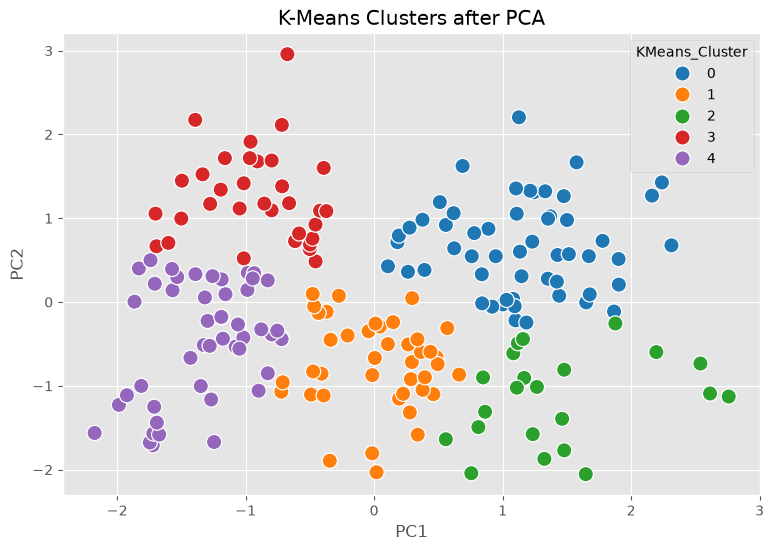

In [10]:
plt.figure(figsize=(9,6))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="KMeans_Cluster",
    palette="tab10",
    s=120
)

plt.title("K-Means Clusters after PCA")

plt.show()

**Cluster Centers**

In [11]:
centers = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=["PC1","PC2"]
)

centers

,PC1,PC2
0,1.138934,0.662549
1,0.022237,-0.739246
2,1.425416,-1.142767
3,-0.917094,1.259568
4,-1.323108,-0.456113


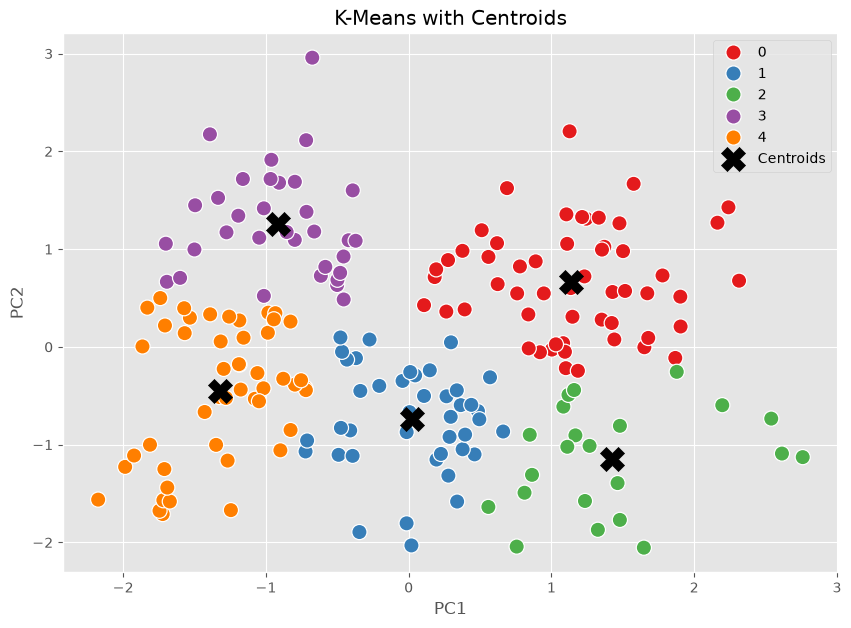

In [12]:
plt.figure(figsize=(10,7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="KMeans_Cluster",
    palette="Set1",
    s=120
)

plt.scatter(
    centers["PC1"],
    centers["PC2"],
    marker="X",
    s=300,
    color="black",
    label="Centroids"
)

plt.legend()

plt.title("K-Means with Centroids")

plt.show()

**Apply DBSCAN**

In [13]:
dbscan = DBSCAN(
    eps=0.8,
    min_samples=5
)

dbscan.fit(pca_df[["PC1","PC2"]])

pca_df["DBSCAN_Cluster"] = dbscan.labels_

pca_df.head()

,PC1,PC2,KMeans_Cluster,DBSCAN_Cluster
0,-0.409677,-0.854725,1,0
1,-1.429194,-0.665974,4,0
2,0.019003,-2.031137,1,0
3,-1.723179,-1.710059,4,0
4,-0.345276,-1.894094,1,0


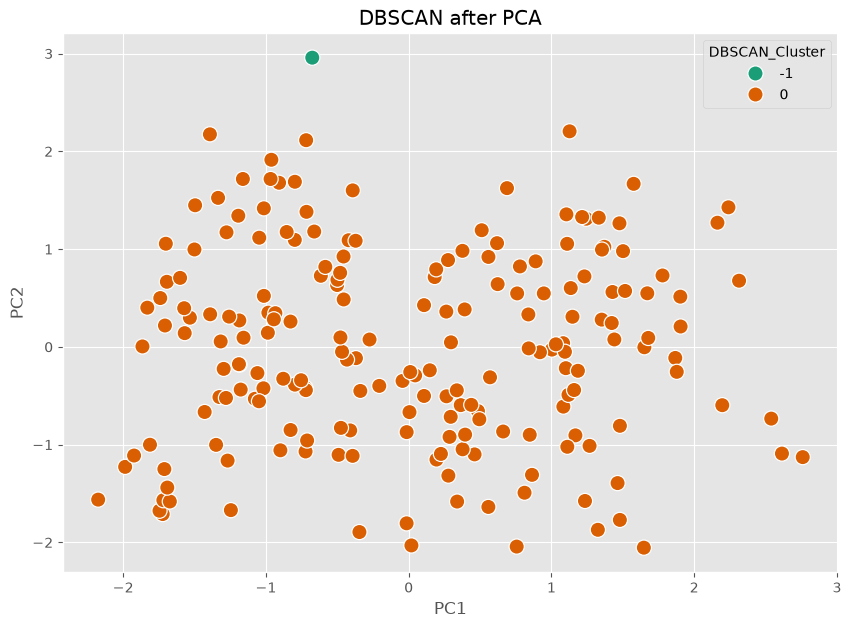

In [14]:
plt.figure(figsize=(10,7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="DBSCAN_Cluster",
    palette="Dark2",
    s=120
)

plt.title("DBSCAN after PCA")

plt.show()

In [15]:
print("DBSCAN Labels")

print(pca_df["DBSCAN_Cluster"].unique())

DBSCAN Labels
[ 0 -1]


**KMeans Distribution**

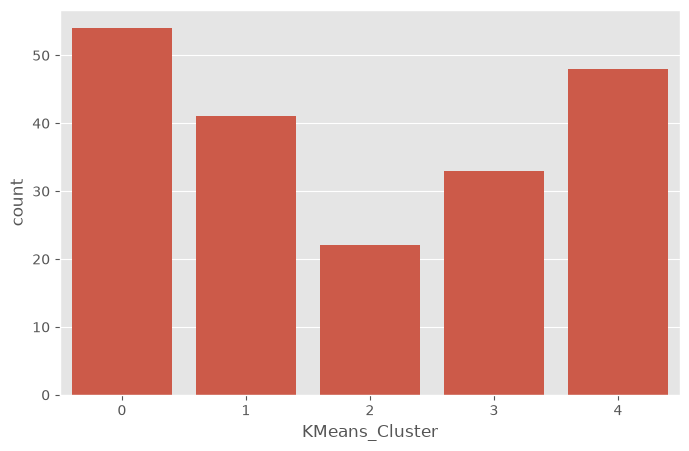

In [16]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=pca_df,
    x="KMeans_Cluster"
)

plt.show()

**DBSCAN Distribution**

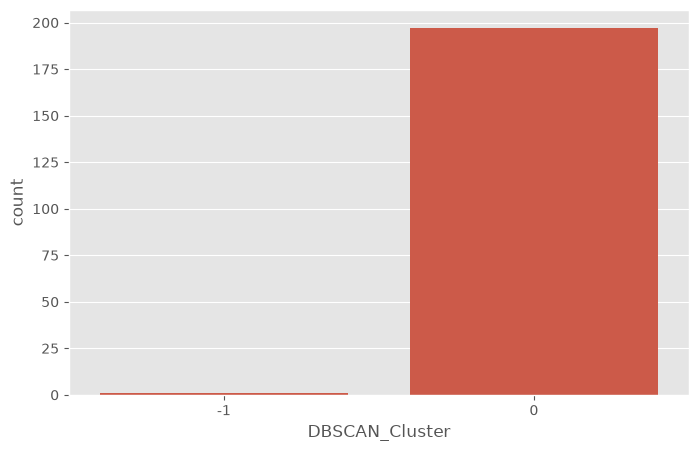

In [17]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=pca_df,
    x="DBSCAN_Cluster"
)

plt.show()

**Correlation**

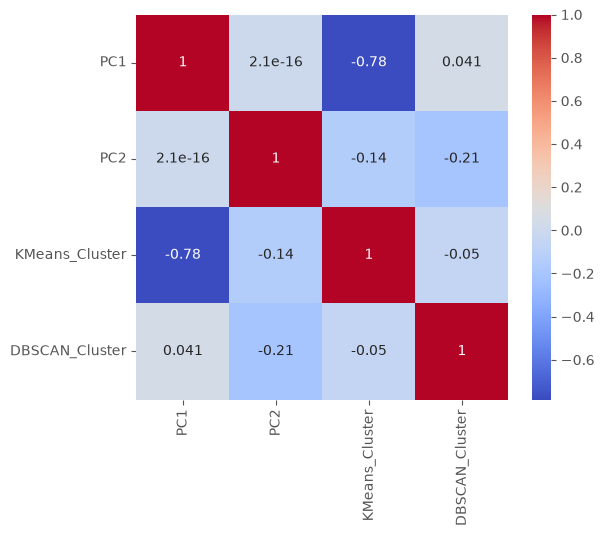

In [18]:
plt.figure(figsize=(6,5))

sns.heatmap(
    pca_df.corr(),
    annot=True,
    cmap="coolwarm"
)

plt.show()

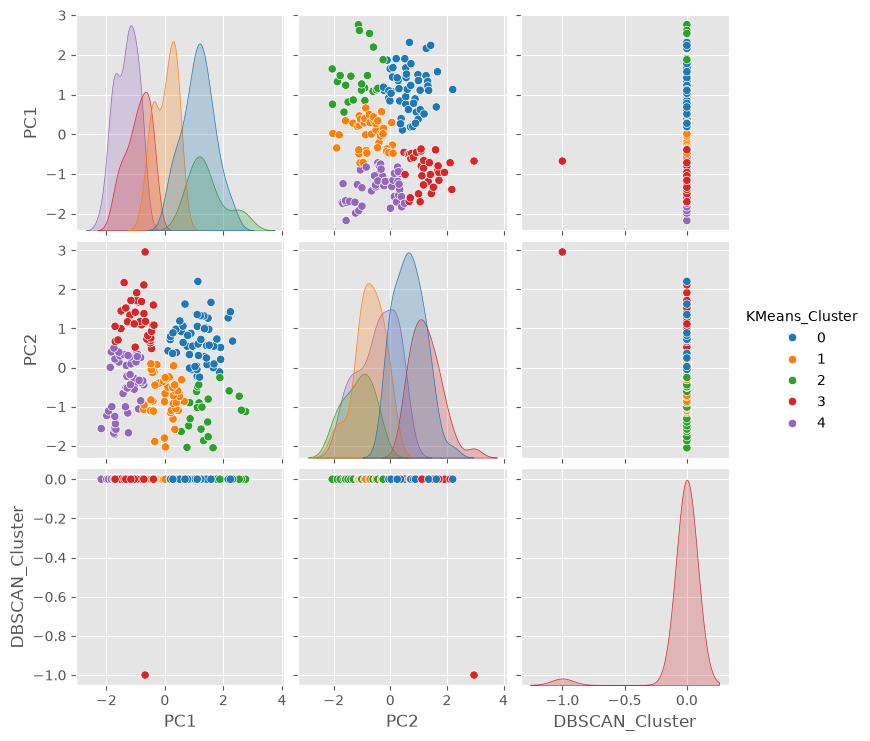

In [19]:
sns.pairplot(
    pca_df,
    hue="KMeans_Cluster",
    palette="tab10"
)

plt.show()

In [20]:
pca_df.to_csv(
    "../data/pca_customer_data.csv",
    index=False
)

print("PCA dataset saved successfully!")

PCA dataset saved successfully!


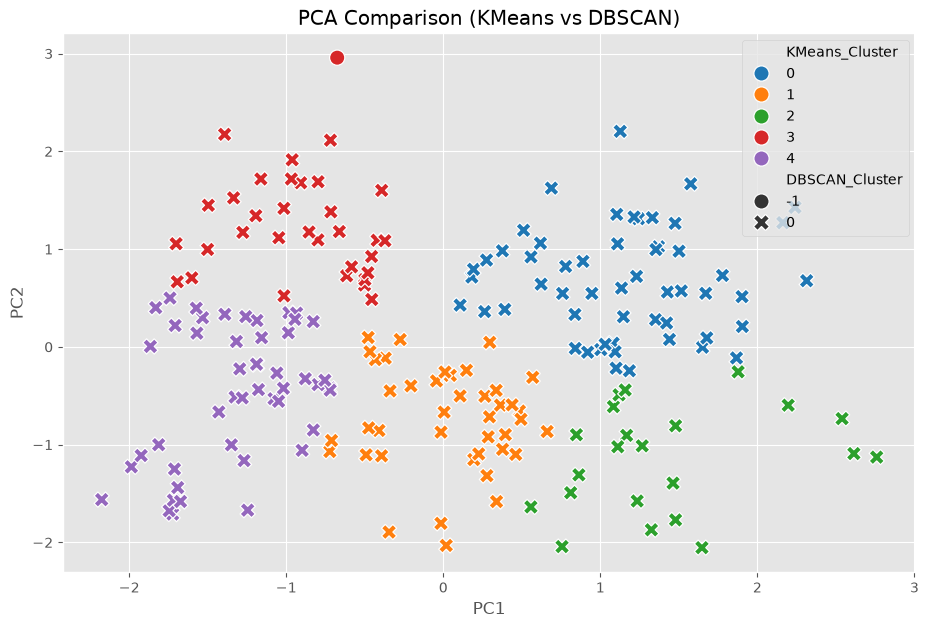

In [21]:
plt.figure(figsize=(11,7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="KMeans_Cluster",
    style="DBSCAN_Cluster",
    palette="tab10",
    s=120
)

plt.title("PCA Comparison (KMeans vs DBSCAN)")

plt.show()